In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("retail_train.csv")

In [4]:
df

,SessionID,Pages_Visited,Time_Spent,Cart_Items_Count,Device_Type,Is_Weekend,Server_Cluster_ID,Made_Purchase
0,SES_0,5,208.8 Secs,2,Desktop,1,CLU_0,0
1,SES_1,4,155.6 Secs,0,Mobile,1,CLU_1,0
2,SES_2,4,168.6 Secs,4,Desktop,0,CLU_2,1
3,SES_3,3,266.9 Secs,0,Desktop,1,CLU_3,0
4,SES_4,2,104.4 Secs,2,Mobile,0,CLU_4,1
...,...,...,...,...,...,...,...,...
5995,SES_5995,4,262.6 Secs,2,Mobile,1,CLU_5995,0
5996,SES_5996,3,NaN,2,Mobile,0,CLU_5996,1
5997,SES_5997,7,244.2 Secs,2,Desktop,0,CLU_5997,1
5998,SES_5998,3,243.4 Secs,3,Desktop,0,CLU_5998,1


In [5]:
df.drop(['SessionID', 'Server_Cluster_ID'], axis=1, inplace=True)

In [6]:
df.columns

Index(['Pages_Visited', 'Time_Spent', 'Cart_Items_Count', 'Device_Type',
       'Is_Weekend', 'Made_Purchase'],
      dtype='str')

In [7]:
df.shape

(6000, 6)

In [8]:
df.dtypes

Pages_Visited       int64
Time_Spent            str
Cart_Items_Count    int64
Device_Type           str
Is_Weekend          int64
Made_Purchase       int64
dtype: object

In [9]:
df2=df['Device_Type'].value_counts()
df2

Device_Type
Mobile     2711
Desktop    2705
Tablet      283
Name: count, dtype: int64

In [10]:
df['Device_Type'].unique()

<StringArray>
['Desktop', 'Mobile', 'Tablet', nan]
Length: 4, dtype: str

In [11]:
df['Time_Spent'].unique()

<StringArray>
['208.8 Secs', '155.6 Secs', '168.6 Secs', '266.9 Secs', '104.4 Secs',
 '303.8 Secs', '169.1 Secs', '243.2 Secs', '101.7 Secs', '411.9 Secs',
 ...
 '183.7 Secs', '381.0 Secs', '505.0 Secs', '622.2 Secs', '750.2 Secs',
 '119.0 Secs', '457.7 Secs', '680.3 Secs', '388.5 Secs', '416.5 Secs']
Length: 3519, dtype: str

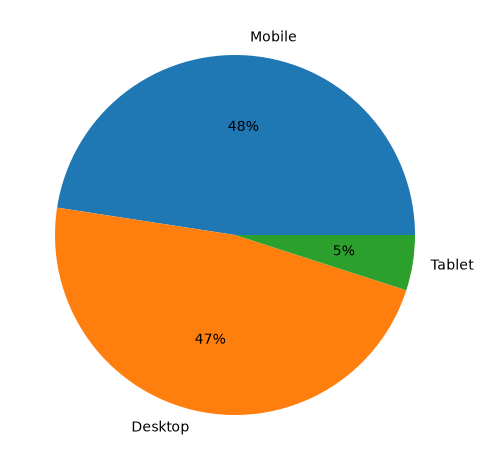

In [12]:
plt.pie(df2.values,labels=df2.index,autopct='%2.f%%')
plt.tight_layout()

In [13]:
df

,Pages_Visited,Time_Spent,Cart_Items_Count,Device_Type,Is_Weekend,Made_Purchase
0,5,208.8 Secs,2,Desktop,1,0
1,4,155.6 Secs,0,Mobile,1,0
2,4,168.6 Secs,4,Desktop,0,1
3,3,266.9 Secs,0,Desktop,1,0
4,2,104.4 Secs,2,Mobile,0,1
...,...,...,...,...,...,...
5995,4,262.6 Secs,2,Mobile,1,0
5996,3,NaN,2,Mobile,0,1
5997,7,244.2 Secs,2,Desktop,0,1
5998,3,243.4 Secs,3,Desktop,0,1


In [14]:
df.dtypes

Pages_Visited       int64
Time_Spent            str
Cart_Items_Count    int64
Device_Type           str
Is_Weekend          int64
Made_Purchase       int64
dtype: object

In [15]:
df['Time_Spent']=df['Time_Spent'].str.replace('Secs', '').astype(float)

In [16]:
df.isna().sum()

Pages_Visited         0
Time_Spent          279
Cart_Items_Count      0
Device_Type         301
Is_Weekend            0
Made_Purchase         0
dtype: int64

In [17]:
df['Time_Spent']=df['Time_Spent'].fillna(df['Time_Spent'].median())

In [18]:
df['Device_Type']=df['Device_Type'].fillna(df['Device_Type'].mode()[0])

In [19]:
df_d=pd.get_dummies(df[['Device_Type']], drop_first=True, dtype=int)

In [20]:
df_e=pd.concat([df, df_d], axis=1)

In [21]:
df_e.drop(columns=['Device_Type'], inplace=True)

In [22]:
df_e.isna().sum()

Pages_Visited         0
Time_Spent            0
Cart_Items_Count      0
Is_Weekend            0
Made_Purchase         0
Device_Type_Mobile    0
Device_Type_Tablet    0
dtype: int64

In [23]:
df_e.dtypes

Pages_Visited           int64
Time_Spent            float64
Cart_Items_Count        int64
Is_Weekend              int64
Made_Purchase           int64
Device_Type_Mobile      int64
Device_Type_Tablet      int64
dtype: object

In [24]:
df_e.head()

,Pages_Visited,Time_Spent,Cart_Items_Count,Is_Weekend,Made_Purchase,Device_Type_Mobile,Device_Type_Tablet
0,5,208.8,2,1,0,0,0
1,4,155.6,0,1,0,1,0
2,4,168.6,4,0,1,0,0
3,3,266.9,0,1,0,0,0
4,2,104.4,2,0,1,1,0


In [25]:
df3=df_e['Made_Purchase'].value_counts()
df3

Made_Purchase
0    3220
1    2780
Name: count, dtype: int64

Text(0, 0.5, 'Count')

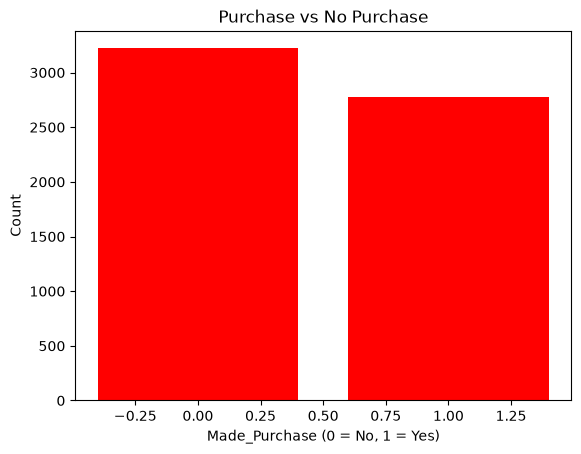

In [26]:
plt.bar(df3.index,df3.values,color='r')
plt.title('Purchase vs No Purchase')
plt.xlabel('Made_Purchase (0 = No, 1 = Yes)')
plt.ylabel('Count')

In [27]:
df_e

,Pages_Visited,Time_Spent,Cart_Items_Count,Is_Weekend,Made_Purchase,Device_Type_Mobile,Device_Type_Tablet
0,5,208.8,2,1,0,0,0
1,4,155.6,0,1,0,1,0
2,4,168.6,4,0,1,0,0
3,3,266.9,0,1,0,0,0
4,2,104.4,2,0,1,1,0
...,...,...,...,...,...,...,...
5995,4,262.6,2,1,0,1,0
5996,3,267.9,2,0,1,1,0
5997,7,244.2,2,0,1,0,0
5998,3,243.4,3,0,1,0,0


In [28]:
df_e.columns

Index(['Pages_Visited', 'Time_Spent', 'Cart_Items_Count', 'Is_Weekend',
       'Made_Purchase', 'Device_Type_Mobile', 'Device_Type_Tablet'],
      dtype='str')

In [29]:
df2=pd.read_csv("retail_test.csv")

In [30]:
df2.head()

,SessionID,Pages_Visited,Time_Spent,Cart_Items_Count,Device_Type,Is_Weekend
0,SES_6000,7,347.1 Secs,0,Desktop,0
1,SES_6001,4,179.8 Secs,4,Mobile,0
2,SES_6002,3,103.0 Secs,1,Mobile,0
3,SES_6003,4,158.7 Secs,4,Mobile,0
4,SES_6004,8,383.7 Secs,5,Desktop,0


In [31]:
df_e.columns

Index(['Pages_Visited', 'Time_Spent', 'Cart_Items_Count', 'Is_Weekend',
       'Made_Purchase', 'Device_Type_Mobile', 'Device_Type_Tablet'],
      dtype='str')

In [32]:
df2

,SessionID,Pages_Visited,Time_Spent,Cart_Items_Count,Device_Type,Is_Weekend
0,SES_6000,7,347.1 Secs,0,Desktop,0
1,SES_6001,4,179.8 Secs,4,Mobile,0
2,SES_6002,3,103.0 Secs,1,Mobile,0
3,SES_6003,4,158.7 Secs,4,Mobile,0
4,SES_6004,8,383.7 Secs,5,Desktop,0
...,...,...,...,...,...,...
1495,SES_7495,5,261.3 Secs,5,Desktop,0
1496,SES_7496,8,484.8 Secs,2,Desktop,1
1497,SES_7497,4,342.0 Secs,3,Desktop,1
1498,SES_7498,5,245.5 Secs,3,Desktop,0


In [33]:
test_ids=df2['SessionID'].copy()
df2.drop(columns=['SessionID'], inplace=True)

In [34]:
df2.dtypes

Pages_Visited       int64
Time_Spent            str
Cart_Items_Count    int64
Device_Type           str
Is_Weekend          int64
dtype: object

In [35]:
df2['Time_Spent']=df2['Time_Spent'].str.replace('Secs', '').astype(float)

In [36]:
df2.isna().sum()

Pages_Visited        0
Time_Spent          55
Cart_Items_Count     0
Device_Type         63
Is_Weekend           0
dtype: int64

In [37]:
df2.dtypes

Pages_Visited         int64
Time_Spent          float64
Cart_Items_Count      int64
Device_Type             str
Is_Weekend            int64
dtype: object

In [38]:
df2['Time_Spent']=df2['Time_Spent'].fillna(df['Time_Spent'].median())

In [39]:
df2['Device_Type']=df2['Device_Type'].fillna(df['Device_Type'].mode()[0])

In [40]:
x=df_e.drop(columns=['Made_Purchase'])
y=df_e['Made_Purchase']

In [41]:
x

,Pages_Visited,Time_Spent,Cart_Items_Count,Is_Weekend,Device_Type_Mobile,Device_Type_Tablet
0,5,208.8,2,1,0,0
1,4,155.6,0,1,1,0
2,4,168.6,4,0,0,0
3,3,266.9,0,1,0,0
4,2,104.4,2,0,1,0
...,...,...,...,...,...,...
5995,4,262.6,2,1,1,0
5996,3,267.9,2,0,1,0
5997,7,244.2,2,0,0,0
5998,3,243.4,3,0,0,0


In [42]:
df2.head()

,Pages_Visited,Time_Spent,Cart_Items_Count,Device_Type,Is_Weekend
0,7,347.1,0,Desktop,0
1,4,179.8,4,Mobile,0
2,3,103.0,1,Mobile,0
3,4,158.7,4,Mobile,0
4,8,383.7,5,Desktop,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,confusion_matrix

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

models={
    'KNN':KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes':GaussianNB(),
    'SVC':SVC(),
    'Decision Tree':DecisionTreeClassifier()
    }

model_scores = {}
for key,values in models.items():
    values.fit(x_train,y_train)
    y_pred2=values.predict(x_test)
    model_scores[key]=accuracy_score(y_test,y_pred2)
    print(f'{key} accuracy:{model_scores[key]}')
    print(confusion_matrix(y_test,y_pred2))

KNN accuracy:0.645
[[441 215]
 [211 333]]
Naive Bayes accuracy:0.6683333333333333
[[494 162]
 [236 308]]
SVC accuracy:0.6766666666666666
[[492 164]
 [224 320]]
Decision Tree accuracy:0.5975
[[406 250]
 [233 311]]


In [44]:
df2_d = pd.get_dummies(df2[['Device_Type']], drop_first=True, dtype=int)
df2 = pd.concat([df2, df2_d], axis=1)
df2.drop(columns=['Device_Type'], inplace=True)

df2 = df2.reindex(columns=x.columns, fill_value=0)

print("Training feature shape:", x.shape)
print("Test feature shape:", df2.shape)
print("Missing values in test features:")
print(df2.isna().sum())

Training feature shape: (6000, 6)
Test feature shape: (1500, 6)
Missing values in test features:
Pages_Visited         0
Time_Spent            0
Cart_Items_Count      0
Is_Weekend            0
Device_Type_Mobile    0
Device_Type_Tablet    0
dtype: int64


In [47]:
best_model_name=max(model_scores, key=model_scores.get)
best_model=models[best_model_name]

print("Best model:",best_model_name)
print(f"Best validation accuracy: {model_scores[best_model_name]}")


final_scaler=StandardScaler()
x_full_scaled=final_scaler.fit_transform(x)
test_scaled=final_scaler.transform(df2)


best_model.fit(x_full_scaled, y)


final_predictions=best_model.predict(test_scaled)

print("Number of predictions:", len(final_predictions))
print(pd.Series(final_predictions).value_counts().sort_index())

Best model: SVC
Best validation accuracy: 0.6766666666666666
Number of predictions: 1500
0    889
1    611
Name: count, dtype: int64


In [46]:
submission = pd.DataFrame({
    'SessionID': test_ids,
    'Made_Purchase': final_predictions
})

submission.to_csv("predictions_final.csv", index=False)

print(submission.head())
print("Saved predictions_final.csv with", len(submission), "rows.")

  SessionID  Made_Purchase
0  SES_6000              1
1  SES_6001              1
2  SES_6002              0
3  SES_6003              1
4  SES_6004              1
Saved predictions_final.csv with 1500 rows.
